In [1]:
# SECTION 1 — Imports and configuration
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score
from torch.optim.lr_scheduler import ReduceLROnPlateau

import warnings
warnings.filterwarnings('ignore')

# REPRODUCIBILITY
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# KAGGLE SAFETY: Print device info
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("CUDA availability:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

# Local project paths
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT.name != "OcuVision-AI" and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results" / "vit_b16"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODELS_DIR / "vit_b16_best_checkpoint.pth"
history_path = RESULTS_DIR / "vit_b16_training_history.csv"

print("Project root:", PROJECT_ROOT)
print("Checkpoint:", checkpoint_path)
print("History:", history_path)


PyTorch version: 2.11.0+cu128
CUDA availability: True
GPU name: NVIDIA GeForce RTX 4050 Laptop GPU
Project root: D:\gpt\OcuVision-AI
Checkpoint: D:\gpt\OcuVision-AI\models\vit_b16_best_checkpoint.pth
History: D:\gpt\OcuVision-AI\results\vit_b16\vit_b16_training_history.csv


In [2]:
# SECTION 2 — Local dataset verification

base_path = PROJECT_ROOT / "data" / "preprocessed"

total = 0
bad = []

if base_path.exists():
    print("Dataset path:", base_path)

    for cls in sorted(os.listdir(base_path)):
        folder = base_path / cls

        if not folder.is_dir():
            continue

        for filename in os.listdir(folder):
            path = folder / filename
            total += 1

            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception as e:
                bad.append((filename, str(e)))

    print("Number of images:", total)
    print("Bad/unreadable images:", len(bad))
else:
    print(f"Dataset path {base_path} not found.")

Dataset path: D:\gpt\OcuVision-AI\data\preprocessed
Number of images: 10449
Bad/unreadable images: 0


In [3]:
# SECTION 3 — Class mapping

class_to_idx = {
    "N": 0,
    "D": 1,
    "G": 2,
    "C": 3,
    "A": 4,
    "H": 5,
    "M": 6
}

idx_to_class = {v: k for k, v in class_to_idx.items()}
classes = ["N", "D", "G", "C", "A", "H", "M"]

data = []

if base_path.exists():
    for label in classes:
        folder = base_path / label

        if folder.is_dir():
            for filename in os.listdir(folder):
                data.append({
                    "filename": filename,
                    "label": label,
                    "path": str(folder / filename)
                })

df = pd.DataFrame(data)

print("\nClass distribution:")

if len(df) > 0:
    print(df["label"].value_counts()[classes])
    print("\nTotal images:", len(df))


Class distribution:
label
N    2997
D    3128
G    1646
C    1008
A     511
H     420
M     739
Name: count, dtype: int64

Total images: 10449


In [4]:
# Split
if len(df) > 0:
    train_df, temp_df = train_test_split(
        df,
        test_size=0.20,
        stratify=df["label"],
        random_state=42
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label"],
        random_state=42
    )
    
    # Reset indices
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    print("train/validation/test counts:")
    print("Train:", len(train_df))
    print("Validation:", len(val_df))
    print("Test:", len(test_df))
    
    # Verify no overlap
    train_paths = set(train_df['path'])
    val_paths = set(val_df['path'])
    test_paths = set(test_df['path'])
    
    print("Train/Val overlap:", len(train_paths.intersection(val_paths)))
    print("Train/Test overlap:", len(train_paths.intersection(test_paths)))
    print("Val/Test overlap:", len(val_paths.intersection(test_paths)))


train/validation/test counts:
Train: 8359
Validation: 1045
Test: 1045
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [5]:
# Preprocessing
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [6]:
# SECTION 6 — Dataset and DataLoaders
class OcularDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        label = class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

if len(df) > 0:
    train_dataset = OcularDataset(train_df, train_transform)
    val_dataset = OcularDataset(val_df, eval_transform)
    test_dataset = OcularDataset(test_df, eval_transform)

    batch_size = 64

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    print("DataLoaders created.")


DataLoaders created.


In [7]:
# ViT-B16
if len(df) > 0:
    model = torchvision.models.vit_b_16(
        weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1
    )

    # Replace the classification head for 7 classes
    model.heads.head = nn.Linear(model.heads.head.in_features, 7)
    model = model.to(device)

    # Compute class weights for training
    train_labels = train_df["label"].values

    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.array(classes),
        y=train_labels
    )

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.amp.GradScaler(
        "cuda"
    ) if device.type == "cuda" else torch.amp.GradScaler("cpu")

    print("ViT-B/16 model, criterion, optimizer, and scheduler ready.")

ViT-B/16 model, criterion, optimizer, and scheduler ready.


In [8]:
# Training
def train_epoch(model, dataloader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(dataloader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    val_loss_total = 0.0
    val_preds = []
    val_labels = []

    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Evaluating", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_preds.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(dataloader.dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average="macro")

    return val_loss, val_acc, val_f1, val_preds, val_labels


In [9]:
# SECTION 9 — Training loop with checkpoint saving
if len(df) > 0:
    epochs = 6
    best_val_f1 = 0.0
    best_epoch = -1
    
    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "lr": []
    }

            
    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    for epoch in range(1, epochs + 1):
        print(f"\nEpoch {epoch}/{epochs}")
        
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, device)
        
        current_lr = optimizer.param_groups[0]['lr']
        
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["lr"].append(current_lr)
        
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
        
        scheduler.step(val_f1)
        
        # Checkpoint saving
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            print(f"⭐ New best validation Macro F1: {best_val_f1:.4f}. Saving checkpoint...")
            
            checkpoint = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_val_macro_f1': best_val_f1,
                'class_names': classes
            }
            torch.save(checkpoint, checkpoint_path)
            
        pd.DataFrame(history).to_csv(history_path, index=False)



Epoch 1/6


Training:   0%|          | 0/131 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.9100 | Train Acc: 0.6004
Val Loss:   0.6327 | Val Acc:   0.6651 | Val Macro F1: 0.6709
⭐ New best validation Macro F1: 0.6709. Saving checkpoint...

Epoch 2/6


Training:   0%|          | 0/131 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.3556 | Train Acc: 0.8033
Val Loss:   0.5414 | Val Acc:   0.6890 | Val Macro F1: 0.7029

Epoch 6/6


Training:   0%|          | 0/131 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.2788 | Train Acc: 0.8381
Val Loss:   0.4303 | Val Acc:   0.8019 | Val Macro F1: 0.8193
⭐ New best validation Macro F1: 0.8193. Saving checkpoint...


In [10]:
# SECTION 10 — Restore best checkpoint
if len(df) > 0:
    if os.path.exists(checkpoint_path):
        print(f"Loading best checkpoint...")
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded checkpoint with Validation Macro F1: {checkpoint['best_val_macro_f1']:.4f}")
    else:
        print("Checkpoint not found!")

# Paths
checkpoint_path = '/kaggle/working/vitb16_best.pth'
history_path = '/kaggle/working/vitb16_training_history.csv'


Loading best checkpoint...
Loaded checkpoint with Validation Macro F1: 0.8193


In [11]:
# Evaluation
if len(df) > 0:
    print("Evaluating on test set...")
    test_loss, test_acc, test_macro_f1, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

    test_macro_prec = precision_score(test_labels, test_preds, average="macro")
    test_macro_rec = recall_score(test_labels, test_preds, average="macro")
    test_weighted_f1 = f1_score(test_labels, test_preds, average="weighted")
    
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Test Macro Precision: {test_macro_prec:.4f}")
    print(f"Test Macro Recall: {test_macro_rec:.4f}")
    print(f"Test Macro F1: {test_macro_f1:.4f}")
    print(f"Test Weighted F1: {test_weighted_f1:.4f}")


Evaluating on test set...


Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Test Loss: 0.4143
Test Accuracy: 0.7990
Test Macro Precision: 0.8228
Test Macro Recall: 0.8497
Test Macro F1: 0.8257
Test Weighted F1: 0.7966


In [12]:
# Results
if len(df) > 0:
    print("\nClassification Report:")
    print(classification_report(test_labels, test_preds, target_names=classes, digits=4))



Classification Report:
              precision    recall  f1-score   support

           N     0.6959    0.9030    0.7860       299
           D     0.9179    0.6070    0.7308       313
           G     0.8503    0.7576    0.8013       165
           C     0.9615    0.9901    0.9756       101
           A     0.9796    0.9412    0.9600        51
           H     0.6667    0.8571    0.7500        42
           M     0.6875    0.8919    0.7765        74

    accuracy                         0.7990      1045
   macro avg     0.8228    0.8497    0.8257      1045
weighted avg     0.8245    0.7990    0.7966      1045



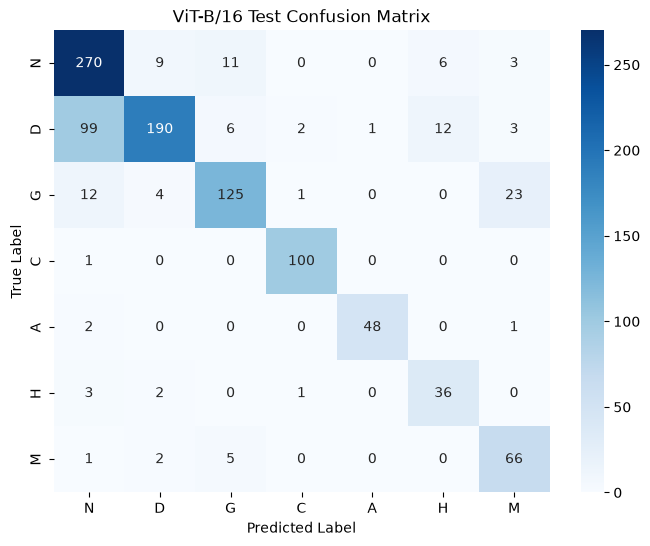

In [13]:
# SECTION 13 — Confusion matrix
if len(df) > 0:
    cm = confusion_matrix(test_labels, test_preds)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title("ViT-B/16 Test Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

In [14]:
# SECTION 14 — Training curves
if len(df) > 0 and os.path.exists(history_path):
    hist_df = pd.read_csv(history_path)
    
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(hist_df['epoch'], hist_df['train_loss'], label='Train Loss', marker='o')
    plt.plot(hist_df['epoch'], hist_df['val_loss'], label='Val Loss', marker='o')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(hist_df['epoch'], hist_df['train_acc'], label='Train Acc', marker='o')
    plt.plot(hist_df['epoch'], hist_df['val_acc'], label='Val Acc', marker='o')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(6, 5))
    plt.plot(hist_df['epoch'], hist_df['val_f1'], label='Val Macro F1', marker='o', color='green')
    plt.title('Validation Macro F1 Score')
    plt.xlabel('Epoch')
    plt.ylabel('Macro F1')
    plt.legend()
    plt.grid(True)
    plt.show()

checkpoint_path = MODELS_DIR / "vit_b16_best_checkpoint.pth"
history_path = RESULTS_DIR / "vit_b16_training_history.csv"


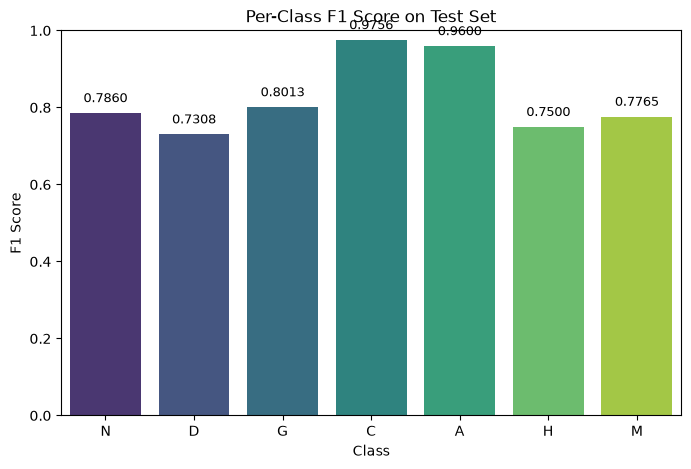

In [15]:
# SECTION 15 — Per-class F1
if len(df) > 0:
    class_f1 = f1_score(test_labels, test_preds, average=None)
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x=classes, y=class_f1, palette='viridis')
    plt.title('Per-Class F1 Score on Test Set')
    plt.xlabel('Class')
    plt.ylabel('F1 Score')
    plt.ylim(0, 1)
    for i, v in enumerate(class_f1):
        plt.text(i, v + 0.02, f"{v:.4f}", ha='center', va='bottom', fontsize=9)
    plt.show()

# Paths
checkpoint_path = MODELS_DIR / "vit_b16_best_checkpoint.pth"
history_path = RESULTS_DIR / "vit_b16_training_history.csv"


In [16]:
# SECTION 16 — External image prediction
def predict_image(img_path, model, transform, device):
    if not os.path.exists(img_path):
        return None
    image = Image.open(img_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            outputs = model(image_tensor)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            pred_idx = probs.argmax(dim=1).item()
            pred_prob = probs[0, pred_idx].item()
    return classes[pred_idx], pred_prob

checkpoint_path = MODELS_DIR / "vit_b16_best_checkpoint.pth"
history_path = RESULTS_DIR / "vit_b16_training_history.csv"


In [17]:
# SECTION 17 — Final checkpoint verification
if len(df) > 0:
    print("\nVIT-B16 EXPERIMENT COMPLETE")
    try:
        print(f"Best validation Macro F1: {best_val_f1:.4f}")
        print(f"Best epoch: {best_epoch}")
    except NameError:
        print("Training variables not in memory (Training was skipped).")

    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Test Macro F1: {test_macro_f1:.4f}")
    print(f"Test Precision: {test_macro_prec:.4f}")
    print(f"Test Recall: {test_macro_rec:.4f}")

    if os.path.exists(checkpoint_path):
        print(f"Checkpoint path: {checkpoint_path}")
        print(f"Checkpoint file size: {os.path.getsize(checkpoint_path) / (1024*1024):.2f} MB")

    if os.path.exists(history_path):
        print(f"Training history path: {history_path}")


VIT-B16 EXPERIMENT COMPLETE
Best validation Macro F1: 0.8193
Best epoch: 6
Test Accuracy: 0.7990
Test Macro F1: 0.8257
Test Precision: 0.8228
Test Recall: 0.8497
Checkpoint path: D:\gpt\OcuVision-AI\models\vit_b16_best_checkpoint.pth
Checkpoint file size: 982.14 MB
Training history path: D:\gpt\OcuVision-AI\results\vit_b16\vit_b16_training_history.csv


In [18]:
# External Validation
# TODO: Future validation on external hospital dataset.
# 1. Load completely separate dataset
# 2. Apply same eval_transform
# 3. Run predictions without retraining
# 4. Compare domain shift metrics
